#  Алгоритмы DQN и PPO в задачах обучения с подкреплением
Конспект содержит анализ базовых методов, математическое описание принципов их оптимизации, а также программную реализацию на базе библиотек `Gymnasium` и `Stable-Baselines3`.

## 1.  Описание алгоритмов


### 1.1 Табличный метод Q-learning

Метод относится к классу алгоритмов временных различий (*Temporal Difference learning*) и предназначен для итерационной аппроксимации функции полезности $Q(s, a)$, отражающей математическое ожидание кумулятивной полезности выполнения действия $a$ в состоянии $s$.

Пересчет временных различий выполняется по правилу стохастической аппроксимации:

$$Q_{k+1}(s, a) = (1 - \alpha) \cdot Q_k(s, a) + \alpha \cdot \hat{Q}(s, a) = Q_k(s, a) + \alpha \cdot \left( \hat{Q}(s, a) - Q_k(s, a) \right)$$

Развертывание оценки $\hat{Q}(s, a)$ через уравнение Беллмана формирует классическое правило обновления:

$$Q(s, a) \leftarrow Q(s, a) + \alpha \cdot \left( r(s, a) + \gamma \cdot \max_{a'} Q(s', a') - Q(s, a) \right)$$

#### Операционный цикл и сбор данных
Алгоритм функционирует в рамках последовательных итераций, сгруппированных в **эпизоды** (игровые сессии от начального состояния до финального/терминального). Данные генерируются непосредственно в процессе взаимодействия со средой («на лету») по следующей схеме:

1. **Инициализация:** В начале каждого эпизода среда сбрасывается в стартовое состояние $s$.
2. **Выбор действия ($\epsilon$-greedy стратегия):** Для обеспечения баланса между исследованием среды (Exploration) и использованием накопленных знаний (Exploitation) агент генерирует случайное число $p \in [0, 1]$.
   * Если $p < \epsilon$, выбирается случайное действие $a \in A$ (стохастическое исследование).
   * Если $p \ge \epsilon$, выбирается жадное действие $a = \arg\max_{a'} Q(s, a')$ (эксплуатация).
   Параметр $\epsilon$ экспоненциально уменьшается с каждым новым эпизодом от $1.0$ до $0.01$.
3. **Получение обратной связи:** Выбранное действие $a$ передается в среду. Среда возвращает мгновенное вознаграждение $r$ и новое состояние $s'$, а также флаг завершения эпизода (`terminated` / `truncated`).
4. **Шаг обновления матрицы:** Используя полученный кортеж данных $(s, a, r, s')$, алгоритм мгновенно модифицирует конкретную ячейку $Q(s, a)$ по формуле Беллмана. Переход к следующему шагу осуществляется присвоением $s \leftarrow s'$.

#### Критерии остановки и объемы данных
Количество просматриваемых эпизодов (обычно от $1\,000$ до $10\,000$ для дискретных сред средней сложности) задается разработчиком. Процесс обучения останавливается при выполнении одного из условий:
* Достижение максимального количества эпизодов (временной критерий).
* Стабилизация матрицы: когда норма разности матрицы между итерациями $\|Q_{k+1} - Q_k\| < \delta$ стремится к нулю (критерий сходимости).

### 1.1.2 Ограничения табличного подхода и необходимость функциональной аппроксимации

Классический метод $Q$-learning не зависит от структуры пространства состояний $\mathcal{S}$ только при условии его конечности и малой размерности. При переходе к непрерывным метрическим пространствам ($\mathcal{S} \subset \mathbb{R}^d$) или задачам с высоким комбинаторным взрывом (высокоразмерные дискретные пространства) точное представление функции полезности $Q(s, a)$ в виде матрицы становится невозможным по двум причинам:

1. **Проклятие размерности (Curse of Dimensionality):** Асимптотический рост объема памяти, требуемого для хранения таблицы коэффициентов, делает вычисления нерекуррентными.
2. **Отсутствие свойства генерализации (Обобщения):** Табличный метод не способен экстраполировать накопленный опыт на не посещенные ранее точки пространства состояний, даже если они находятся в $\epsilon$-окрестности известных дискретных состояний.

Решением является переход от точного матричного представления к параметрической аппроксимации: $Q(s, a) \approx Q_\theta(s, a)$, где $\theta \in \mathbb{R}^m$ - вектор настраиваемых весов непрерывного дифференцируемого отображения, в роли которого выступает глубокая искусственная нейронная сеть (Deep Neural Network).

### 1.1.3 Переход к функциональной аппроксимации

В классической постановке задачи Марковского процесса принятия решений (MDP) для конечных пространств функция полезности $Q(s, a)$ представляется в виде двумерной матрицы. Модификация значений осуществляется прямой перезаписью ячеек по правилу временных различий (TD-error). 

При переходе к непрерывным пространствам состояний ($\mathcal{S} \subseteq \mathbb{R}^d$) точное табличное представление становится невозможным. В рамках глубокого обучения с подкреплением (Deep RL) вся матрица $Q(s, a)$ заменяется единой параметрической функцией $Q_\theta(s, a)$, где роль структуры хранения данных выполняют веса $\theta$ нейросети. Шаг обновления, таким образом, эквивалентен не перезаписи ячейки, а смещению вектора параметров $\theta$ по градиенту функции потерь для минимизации невязки уравнения Беллмана.

### 1.2 Deep Q-Networks - DQN

#### 1.2.1 Описание DQN

При переходе к непрерывным или высокоразмерным пространствам состояний функция полезности параметризуется весами $\theta$ аппроксимирующей ее нейронной сети: $Q(s, a) \approx Q_\theta(s, a)$. На каждой итерации обновление параметров следует выражению:
$$Q_\theta(s, a) \leftarrow Q_\theta(s, a) + \alpha \cdot \left( r(s, a) + \gamma \cdot \max_{a'} Q_\theta(s', a') - Q_\theta(s, a) \right)$$

Это эквивалентно решению задачи регрессии методом простой итерации для уравнения Беллмана:
$$Q^*(s, a) = r(s, a) + \gamma \mathbb{E}_{s'} \left[ \max_{a'} Q^*(s', a') \right]$$

Формализация регрессионного шага для текущей версии параметров $\theta_k$:
* **Входные данные (Признаки):** Вектор состояния среды $s$. Выходной слой сети возвращает вектор размерности $|A|$, где каждый элемент соответствует оценке пары $(s, a)$.
* **Искомое теоретическое значение:** Правая часть уравнения оптимальности Беллмана:
  $$f(s, a) = r(s, a) + \gamma \mathbb{E}_{s'} \left[ \max_{a'} Q^*(s', a') \right]$$
* **Наблюдаемое эмпирическое значение (Таргет $y$):** Одношаговая случайная реализация перехода $s' \sim p(s' | s, a)$:
  $$y(s, a) \leftarrow r(s, a) + \gamma \max_{a'} Q_{\theta_k^-}(s', a')$$
  Где $\theta_k^-$ - замороженные веса целевой сети (*Target Network*).
* **Функция потерь (Loss function):** Среднеквадричная ошибка (MSE) на батче:
  $$Loss(y, \hat{y}) = \frac{1}{2} (y - Q_\theta(s, a))^2$$

---

#### 1.2.2 Обоснование стабилизации градиентного спуска

Применение градиентных методов оптимизации (таких как SGD или Adam) к обучению нейросетевых функций полезности требует выполнения допущения об их независимости и одинаковой распределенности (i.i.d. assumption). В явной схеме взаимодействия агента со средой это допущение нарушается по двум причинам:

1. **Автокорреляция последовательности состояний:** Кортежи опыта, получаемые последовательно во времени, математически зависимы ($\text{Cov}(s_t, s_{t+1}) \neq 0$), что смещает оценку градиента в сторону локальной области пространства состояний. Циклический буфер памяти (Replay Buffer) устраняет временную зависимость посредством рандомизированного сэмплинга мини-батчей.
2. **Нестационарность целевой функции (Moving Targets):** В отличие от стандартной задачи регрессии, где истинные значения (таргеты) $y$ фиксированы, в уравнении Беллмана таргет $y(s, a) = r + \gamma \max_{a'} Q_\theta(s', a')$ сам является функцией от оптимизируемых весов $\theta$. Изменение параметров на каждом шаге приводит к дрейфу целевого распределения, что препятствует сходимости. Введение изолированной целевой сети (Target Network) с замороженными параметрами $\theta^-$ фиксирует распределение целевых значений на заданном интервале шагов, обеспечивая квазистационарность суррогатной функции потерь.

---

#### 1.2.3 Вычислительный цикл и механизмы стабилизации DQN

В отличие от классического Q-learning, глубокая сеть DQN не может обучаться непосредственно на последовательных шагах среды из-за сильной автокорреляции данных. Вычислительный цикл и математические основы его стабилизации организуются следующим образом:

1. **Сбор опыта (Data Collection):** Агент совершает шаг в среде на основе $\epsilon$-greedy стратегии с текущими весами рабочей сети $\theta$. Полученный кортеж опыта $(s_t, a_t, r_t, s_{t+1}, \text{done})$ помещается в циклический буфер памяти (**Replay Buffer**) фиксированной емкости (например, $100\,000$ переходов). Обучение сети не начинается, пока буфер не заполнится до минимального порога (`learning_starts`).
   * *Теоретическое обоснование:* Оптимизация параметров $\theta$ методом стохастического градиентного спуска (SGD) базируется на допущении о независимости и одинаковой распределенности случайных величин (i.i.d. assumption). Траекторные кортежи, генерируемые последовательно во времени, сильно скоррелированы между собой ($\text{Cov}(s_t, s_{t+1}) \neq 0$). Прямое обучение на таком временном потоке смещает вектор градиента в сторону локальной области пространства состояний, вызывая катастрофическое забывание (catastrophic forgetting). `Replay Buffer` декоррелирует данные посредством рандомизированного сэмплинга мини-батчей, преобразуя нестационарный процесс в стационарное распределение для оптимизатора.
2. **Формирование батча (Sampling):** На каждом шаге взаимодействия из буфера памяти случайным образом извлекается пакет данных (мини-батч размером 32, 64 или 128 переходов).
3. **Градиентный спуск:** Для каждого перехода в батче вычисляется целевое значение $y$ с помощью целевой сети $\theta^-$. Рабочая сеть $\theta$ делает предсказание $\hat{y}$. Вычисляется градиент функции потерь $Loss$, и веса $\theta$ обновляются оптимизатором (например, Adam).
4. **Синхронизация сетей:** Каждые $N$ шагов среды (гиперпараметр `target_update_interval`) веса рабочей сети полностью копируются в целевую сеть: $\theta^- \leftarrow \theta$.
   * *Теоретическое обоснование:* При обновлении параметров $\theta$ рабочей сети, целевое значение $y(s, a)$ также является функцией от $\theta$. Изменение весов на каждом шаге приводит к квазихаотическому дрейфу целевой функции распределения потерь (проблема *Moving Targets*), что препятствует сходимости регрессионного шага. Декуплированная архитектура **Target Network** с замороженными параметрами $\theta^-$ фиксирует распределение целевых значений на интервале $N$ шагов, гарантируя квазистационарность суррогатной функции потерь.

---

#### 1.2.3 Критерии остановки и объемы данных
Объем обучения в Deep RL измеряется не эпизодами, а суммарным количеством индивидуальных шагов в среде (`total_timesteps`). Для сред уровня `LunarLander` лимит устанавливается в диапазоне от $100\,000$ до $400\,000$ шагов. Остановка происходит строго по исчерпанию лимита шагов. Признаком успешной сходимости является выход скользящего среднего награды за последние 100 эпизодов на целевое плато (выше $+200$ очков).

---

#### 1.2.4 Ограничения value-based методов в континуальных пространствах действий

Алгоритмы семейства DQN определяют оптимальную стратегию через оператор максимизации: $a = \arg\max_{a'} Q(s, a')$. Этот подход вычислительно эффективен только при конечном дискретном множестве действий $\mathcal{A}$. При переходе к непрерывным пространствам действий ($\mathcal{A} \subseteq \mathbb{R}^m$) операция нахождения точного глобального максимума функции $Q(s, a)$ на каждом временном шаге требует решения ресурсоемкой задачи нелинейного программирования. 

Для преодоления данного ограничения применяются прямые градиентные методы стратегии (Policy Gradient), в частности архитектура Actor-Critic (Актор-Критик). В этой схеме сеть Актора напрямую параметризует непрерывное распределение вероятностей действий $\pi_\theta(a|s)$ (например, вычисляя математическое ожидание $\mu$ и дисперсию $\sigma$ для многомерного распределения Гаусса), исключая необходимость аналитического или численного поиска максимума по пространству действий.

### 1.3 Proximal Policy Optimization - PPO

В отличие от value-based методов, PPO относится к категории градиентных алгоритмов стратегии (Policy Gradient). Архитектура состоит из двух нейронных сетей: **Актора (Actor)**, который напрямую параметризует стохастическую стратегию $\pi_\theta(a|s)$ (определяет вероятности действий), и **Критика (Critic)**, оценивающего ценность состояний $V_\phi(s)$.

Оптимизация параметров стратегии $\theta$ осуществляется путем максимизации специализированной суррогатной целевой функции (Clipped Objective Function):
$$L^{CLIP}(\theta) = \hat{\mathbb{E}}_t \left[ \min\left(r_t(\theta)\hat{A}_t, \, \text{clip}(r_t(\theta), 1-\epsilon, 1+\epsilon)\hat{A}_t\right) \right]$$

где:
* $r_t(\theta) = \frac{\pi_\theta(a_t|s_t)}{\pi_{\theta_{old}}(a_t|s_t)}$ — относительное изменение вероятности выбора действия новой стратегией по сравнению с предыдущей.
* $\hat{A}_t$ — функция преимущества (Advantage), рассчитываемая на основе предсказаний Критика $V_\phi(s)$ по методу GAE (Generalized Advantage Estimation). Она показывает, насколько реальная траектория оказалась лучше ожидаемой.
* $\epsilon$ — гиперпараметр срезки (обычно $\epsilon = 0.2$), сдерживающий величину обновления шага.

### 1.3.1 Математический базис функции преимущества (Advantage Function)

В градиентных алгоритмах стратегии базовое использование кумулятивной награды в качестве веса градиента приводит к высокой дисперсии и медленной сходимости. Для стабилизации процесса оптимизации вводится функция преимущества $A(s, a)$, которая измеряет относительную ценность конкретного действия $a$ в состоянии $s$ относительно среднего ожидаемого значения для данного состояния:

$$A(s, a) = Q(s, a) - V(s)$$

Сеть Критика аппроксимирует функцию ценности состояний $V_\phi(s)$, выступая в качестве математического бейзлайна (опорной линии). Если вычисленное по методу GAE (Generalized Advantage Estimation) эмпирическое преимущество $\hat{A}_t$ положительно, это указывает на то, что полученная траектория превосходит среднее ожидание Критика, и алгоритм увеличивает плотность вероятности данного действия в политике Актора. При отрицательном значении математический вес действия уменьшается.

#### Математический смысл операции клиппирования (Clipped Objective)
Алгоритмы прямого градиента стратегии (Policy Gradient) чувствительны к величине шага оптимизации параметров $\theta$. Поскольку сбор данных (Rollout Phase) осуществляется на основе текущей стратегии $\pi_\theta$, чрезмерно сильное изменение вектора весов на одной итерации градиентного спуска может перевести $\pi_\theta$ в субоптимальную область пространства параметров. В этой области ожидаемая кумулятивная награда резко падает. Из-за этого агент теряет способность генерировать репрезентативную выборку траекторий, необходимую для корректного расчета градиента на следующих шагах, что приводит к необратимому расхождению процесса обучения.

Суррогатная функция $L^{CLIP}(\theta)$ реализует концепцию **области доверия (Trust Region)** в рамках оптимизации первого порядка:
* Отношение вероятностей $r_t(\theta) = \frac{\pi_\theta(a_t|s_t)}{\pi_{\theta_{old}}(a_t|s_t)}$ отражает степень изменения новой стратегии относительно параметров предыдущей итерации.
* Оператор $\text{clip}(r_t(\theta), 1-\epsilon, 1+\epsilon)$ ограничивает градиент целевой функции, если изменение параметров приводит к выходу отношения вероятностей за пределы установленного порога $\epsilon$-окрестности.

Таким образом, оптимизатор ограничивает масштаб обновления параметров на основе чрезмерно высоких локальных оценок функции преимущества ($\hat{A}_t$), предотвращая преждевременный коллапс распределения действий и гарантируя монотонное улучшение стратегии (Monotonic Policy Improvement).


#### Архитектура цикла обучения PPO
PPO относится к классу **On-policy** алгоритмов. Он не использует Replay Buffer и обучается строго на тех данных, которые собрала его текущая (самая актуальная) версия политики:

1. **Пакетный сбор данных (Rollout Phase):** Агент взаимодействует со средой исключительно на основе текущих вероятностей стратегии $\pi_\theta$. Он выполняет фиксированное число шагов `n_steps` (например, 2048) во временный буфер. Данные собираются без $\epsilon$-жадного поиска, так как стохастичность (исследование) заложена в сам вероятностный вывод нейросети.
2. **Расчет преимуществ:** После сбора 2048 шагов для всей собранной последовательности вычисляются временные разности и функция преимущества $\hat{A}_t$, а также таргеты для сети Критика.
3. **Эпохи оптимизации (Optimization Phase):** Весь собранный пакет из 2048 шагов делится на мини-батчи (размером `batch_size`, например, 64). Алгоритм совершает $K$ проходов (параметр `n_epochs`, обычно 10) по этому набору данных. На каждом мини-батче обновляются одновременно веса Актера $\theta$ (через $L^{CLIP}$) и веса Критика $\phi$ (через MSE потерю ценности).
4. **Сброс данных:** После завершения всех эпох пакет данных объемом 2048 шагов полностью удаляется из памяти. Агент возвращается к шагу 1 для сбора совершенно нового пакета данных с использованием обновленной политики.

#### Критерии остановки и объемы данных
Как и в DQN, остановка алгоритма PPO происходит по достижению заданного лимита `total_timesteps` (от $100\,000$ до $500\,000$ шагов). Оценка сходимости проводится по графикам суррогатных потерь политики (которые должны стабилизироваться около нуля) и росту функции ценности Критика, минимизирующей ошибку предсказания суммарной награды.

---

#### 1.3.2 Особенности реализации (интерфейсы сопряжения и обертки сред)

В теоретических моделях MDP предполагается, что векторы состояний $\mathcal{S}$ и функции вознаграждения $\mathcal{R}$ поступают на вход алгоритма в предобработанном и стабильном виде. В прикладных задачах глубокого обучения входные физические параметры требуют масштабирования для корректного вычисления градиентов без численного зануления или взрыва параметров.

Использование программных оберток в Stable-Baselines3 решает следующие технологические задачи:
* **`Monitor`:** Осуществляет перехват и протоколирование ненормализованных (истинных) наград и длин эпизодов непосредственно из симулятора, изолируя метрики эффективности от модификаций, производимых нейросетью. Заполняет буфер `ep_info_buffer` для последующего анализа сходимости.
* **`SubprocVecEnv`:** Распараллеливает сбор данных на уровне процессов ОС, выполняя декорреляцию собираемых On-Policy траекторий за счет одновременного сэмплирования из независимых начальных условий среды с несовпадающими значениями случайных зерен (seeds).
* **`VecNormalize`:** Выполняет динамическое смещение и масштабирование векторов состояний и наград к нулевому математическому ожиданию и единичной дисперсии. Это стабилизирует обратное продвижение ошибки (backpropagation) в архитектурах с непрерывными распределениями.


In [ ]:
# Установка необходимых программных пакетов перед началом работы
# !pip install gymnasium[box2d] stable-baselines3 shimmy
# !pip install tensorboard

In [1]:
# ==============================================================================
# ОБЩИЙ БЛОК: ИМПОРТЫ И УНИВЕРСАЛЬНЫЕ ФУНКЦИИ
# ==============================================================================
import gymnasium as gym
import torch
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from stable_baselines3 import DQN, PPO
from stable_baselines3.common.vec_env import SubprocVecEnv, DummyVecEnv, VecNormalize
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.evaluation import evaluate_policy
from stable_baselines3.common.utils import set_random_seed

SEED = 42

def make_env(env_id, rank, seed=0, render_mode="rgb_array"):
    """
    Универсальная функция инициализации изолированного процесса симулятора.
    Каждое окружение оборачивается в Monitor для заполнения ep_info_buffer.
    """
    def _init():
        env = gym.make(env_id, max_episode_steps=400, render_mode=render_mode)
        env = Monitor(env)
        return env
    set_random_seed(seed + rank)
    return _init

def plot_learning_curve(model, title="Динамика обучения агента"):
    """
    Универсальная функция для визуализации кривой обучения моделей DQN и PPO.
    Вычисляет скользящее среднее истории наград из ep_info_buffer.
    """
    if hasattr(model, 'ep_info_buffer') and len(model.ep_info_buffer) > 0:
        rewards = [info['r'] for info in model.ep_info_buffer]
        is_ppo = "PPO" in str(type(model))
        window = 20 if is_ppo else 10
        smoothed_rewards = pd.Series(rewards).rolling(window=window, min_periods=1).mean()
        
        plt.figure(figsize=(10, 5))
        plt.plot(rewards, alpha=0.25, color='blue', label='Награда за эпизод')
        plt.plot(smoothed_rewards, color='red', linewidth=2, label=f'Скользящее среднее (окно {window})')
        plt.axhline(y=200, color='green', linestyle='--', label='Target-плато (+200)')
        plt.title(title, fontsize=14)
        plt.xlabel('Завершенные эпизоды (Rollout-логи)', fontsize=12)
        plt.ylabel('Кумулятивная награда за эпизод', fontsize=12)
        plt.grid(True, linestyle=':', alpha=0.6)
        plt.legend(loc='lower right')
        plt.show()
    else:
        print("Данные ep_info_buffer отсутствуют. Проверьте наличие Monitor и вызов .learn().")

## 2. Программная реализация DQN в среде LunarLander-v3

### 2.1 Дискретное пространство состояний: DQN в среде LunarLander-v3

#### 2.1.1 Описание среды и функции вознаграждения

Для формирования управляющего воздействия агент на каждом временном шаге $t$ принимает вектор состояния $S_t \in \mathbb{R}^8$, содержащий следующие физические переменные:
*   $S_0, S_1$ - декартовы координаты центра масс аппарата по осям X и Y относительно центра посадочной площадки.
*   $S_2, S_3$ - линейные скорости перемещения по осям X и Y.
*   $S_4$ - угол отклонения продольной оси аппарата от вертикали (тангаж).
*   $S_5$ - угловая скорость вращения корпуса.
*   $S_6, S_7$ - дискретные индикаторы (0 или 1) физического контакта левой и правой посадочных опор с поверхностью.

Кумулятивное вознаграждение за эпизод формируется как линейная комбинация шаговых штрафов и терминальных бонусов:
1. **Дистанционная составляющая:** Положительный стимул, пропорциональный уменьшению евклидова расстояния до целевой точки $(0, 0)$ и минимизации линейных скоростей $S_2, S_3$ (диапазон от $+100$ до $+140$ очков).
2. **Потери на стабилизацию тангажа:** Непрерывный штраф за ненулевые значения угла наклона $S_4$ и угловой скорости $S_5$.
3. **Затраты на управление (расход топлива):** Дискретный вычет $-0.3$ очка за каждый шаг активности главного двигателя и $-0.03$ очка за шаг активности боковых микродвигателей.
4. **Финальный предикат завершения эпизода:** Добавление терминального бонуса $+100$ очков при успешной стабилизации на площадке с нулевой скоростью или штрафа $-100$ очков при механическом разрушении аппарата (аварии при посадке).

---

#### 2.1.2 Конфигурация гиперпараметров и выбор модели DQN в среде LunarLander-v3

При реализации базовой архитектуры Deep Q-Network для дискретной среды стандартная полносвязная сеть расширяется до двух слоев по 256 нейронов (`net_arch=[256, 256]`), а в качестве функции активации применяется гиперболический тангенс (`torch.nn.Tanh`). 

* **Выбор функции активации в знакопеременных пространствах:** Выбор нелинейности обусловлен топологией вектора состояния $\mathcal{S} \in \mathbb{R}^8$. Использование полунепрерывного линейного выпрямителя (`ReLU`), зануляющего область отрицательных значений $\mathbb{R}^-$, приводит к потере градиентной чувствительности сети (эффект *dying ReLU*) при обработке инвертированных знаков физических переменных. В частности, при отрицательном значении декартовой координаты ($S_0 < 0$, нахождение левее центра посадочной площадки) или векторов скоростей ($S_2, S_3 < 0$), знакосимметричная функция активации `Tanh` сохраняет знак аргумента в интервале $[-1, 1]$, обеспечивая корректный расчет знака управляющего момента сил.

В процессе оптимизации DQN склонен находить субоптимальный локальный экстремум - стратегию непрерывного парения над площадкой. Агент стремится бесконечно расходовать топливо, избегая риска аварии (штраф $-100$ очков). 

* **Природа эффекта квазистационарного парения:** Данный дефект возникает, когда дифференциальная положительная награда за удержание высоты и минимизацию угловых скоростей математически перевешивает дисконтированное математическое ожидание терминального штрафа за потенциальнуюварию при попытке контакта с поверхностью. Искусственное ограничение длины эпизода (`max_episode_steps=400`) переводит задачу в класс процессов с жестким конечным горизонтом (Finite Horizon MDP). Это лишает агента возможности бесконечной кумуляции промежуточных наград за удержание высоты, вынуждая его оптимизировать траекторию сближения с целевой посадочной площадкой.

Дополнительно для стабилизации целей регрессии применяется схема мягкого Поляковского усреднения весов целевой сети с коэффициентом `tau=0.005` на каждом шаге среды (`train_freq=2`). Если веса оптимизатора дестабилизируются из-за высокой плотности шума непосредственно у поверхности земли, это выражается в колебаниях аппарата в метре от площадки. В этом случае необходимо увеличить размер обучающего пакета `batch_size` до 128 для сглаживания стохастического шума и поднять порог `learning_starts` до 15 000 шагов, формируя избыточный буфер репликации (`Replay Buffer`) до начала первого градиентного спуска.

---

#### 2.1.3 Коррекция ошибок обучения

В таблице зафиксированы причинно-следственные связи между наблюдаемыми отклонениями в поведении агента и способами их устранения через регулирование гиперпараметров.

| Характер дефекта поведения агента | Возможная причина аномалии | Корректируемый гиперпараметр | Механизм воздействия и целевое значение |
| :--- | :--- | :--- | :--- |
| **Агент зависает в воздухе над площадкой, непрерывно расходуя топливо** | Локальный максимум целевой функции: промежуточные очки за удержание высоты перевешивают риск падения. Целевые значения регрессии нестабильны. | `max_episode_steps`<br><br><br>`tau`<br><br><br>`learning_starts` | **Снижение** лимита шагов с 600 до 300–400 для принудительного отсечения бесконечных циклов парения.<br>**Перевод** на мягкое Поляковское усреднение (`tau=0.005`) для плавной стабилизации целей регрессии.<br>**Увеличение** до 15 000 шагов для первоначального накопления разнообразного опыта приземлений. |
| **Аппарат смещается по горизонтали за пределы экрана без попыток возврата** | Градиент влияния боковых признаков ($S_0, S_2$) в функции потерь подавлен вертикальными компонентами. Краткосрочный горизонт планирования. | `activation_fn`<br><br><br>`gamma`<br><br><br>`train_freq` | **Замена** `ReLU` на `torch.nn.Tanh` для восстановления чувствительности сети к отрицательным координатам.<br>**Повышение** до `0.995` при итерациях с высоким боковым сносом для учета долгосрочных терминальных штрафов.<br>**Снижение** до 1 или 2 шагов для увеличения частоты оптимизации весов при фиксации микро-сдвигов. |
| **Агент совершает хаотичные колебания у поверхности земли, приводящие к крашу** | Высокая автокорреляция последовательных кадров на финальном этапе. Переобучение сети на зашумленной выборке. | `batch_size`<br><br><br>`n_steps` (для многошагового DQN) | **Увеличение** объема сэмплирования пакета до 128 для сглаживания стохастического шума градиента.<br>**Увеличение** интервала расчета временных различий (TD-error) до `n_steps=3` для оценки долгосрочных последствий сближения. |

### 2.2 Обучение агента и сохранение параметров

In [ ]:
if __name__ == '__main__':
    # Инициализация однопоточной среды для дискретного алгоритма value-based
    env_dqn = DummyVecEnv([make_env("LunarLander-v3", rank=0, seed=SEED)])
    
    model_dqn = DQN(
        policy="MlpPolicy",
        env=env_dqn,
        tensorboard_log="./dqn_lunar_tensorboard/",
        # Математические параметры сходимости:
        learning_rate=2e-4,          # Скорость обучения, оптимизированная для знакосимметричной функции Tanh
        buffer_size=200000,          # Предельная емкость циклического буфера репликации (Replay Buffer)
        learning_starts=15000,       # Объем априорной выборки, собираемой случайной стратегией до первого шага SGD
        batch_size=128,              # Размер мини-батча для декорреляции стохастического шума градиента
        gamma=0.99,                  # Дисконтирующий множитель для установления долгосрочного горизонта планирования
    
        # Частота обновления градиентов и стабилизация целей:
        train_freq=2,                # Периодичность оптимизации весов (шаги градиентного спуска на шаги среды)
        tau=0.005,                   # Коэффициент мягкого Поляковского усреднения весов целевой сети (Target Network)
        target_update_interval=1,    # Интервал синхронизации (равен 1 при непрерывном обновлении через tau)
        max_grad_norm=10,            # Ограничение нормы градиента для предотвращения расхождения весов
    
        # Управление графиком стохастического исследования распределения (Exploration):
        exploration_fraction=0.50,   # Доля общего времени обучения, выделенная на линейное снижение параметра epsilon
        exploration_final_eps=0.02,  # Асимптотический минимальный порог стохастичности стратегии агента
    
        # Топология аппроксиматора и функции активации:
        policy_kwargs=dict(
            net_arch=[256, 256],          # Полносвязная двухслойная архитектура скрытых слоев
            activation_fn=torch.nn.Tanh   # Знакосимметричная функция нелинейности для сохранения знака координат
        ),
        seed=SEED,
        verbose=1
    )
    
    print("Запуск процесса оптимизации параметров DQN...")
    model_dqn.learn(total_timesteps=220000, progress_bar=True)
    
    # Фиксация весовых коэффициентов обученной модели
    model_dqn.save("dqn_lunar_solved")
    env_dqn.close()

### 2.3 Чтение сохраненных результатов (загрузка данных)

In [2]:
# Восстановление объекта обученного агента из zip-архива
env_dqn_eval = DummyVecEnv([make_env("LunarLander-v3", rank=0, seed=SEED, render_mode="human")])
model_dqn_loaded = DQN.load("dqn_lunar_solved", env=env_dqn_eval)

### 2.4 Визуализация кривой обучения (Learning Curve) и вызов TensorBoard

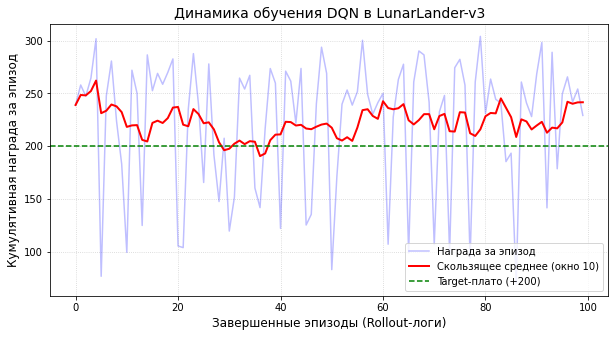

In [3]:
# Отрисовка графика на основе данных заполненного ep_info_buffer
plot_learning_curve(model_dqn_loaded, title="Динамика обучения DQN в LunarLander-v3")

In [ ]:
import os

%load_ext tensorboard

log_dir_raw = os.path.abspath("dqn_lunar_tensorboard")
log_dir_absolute = f'"{log_dir_raw}"'

print(f"Экранированный путь: {log_dir_absolute}")

# Запуск расширения с явным синтаксисом
%tensorboard --logdir=$log_dir_absolute

### 2.5 Анализ результатов обучения

На основе сопоставления локальной кривой обучения (`plot_learning_curve`) и временных рядов TensorBoard (интервал 0–220 000 шагов) фиксируются следующие численные и поведенческие закономерности:

1. **Динамика сходимости и максимизация награды (`rollout/ep_rew_mean`):**
   Процесс обучения демонстрирует стабильный монотонный рост средней кумулятивной награды за эпизод. До отметки 40 000 шагов агент демонстрирует отрицательную эффективность (на уровне -200 очков) из-за преобладания случайного поиска. Переломный момент и выход в положительную зону наград фиксируется на интервале 50 000–600 000 шагов. На финальном этапе (220 000 шагов) средняя скользящая награда достигает **222.71 очка**, что стабильно превышает нормативный порог решения среды ($Target = +200$).

2. **Временной профиль эпизодов и дефект «парения» (`rollout/ep_len_mean`):**
   График средней длины эпизода имеет куполообразный вид. На этапе случайного поиска (0–50k шагов) длительность минимальна ($\sim 100$ шагов) из-за частых аварий. На этапе интенсивного обучения (50k–120k шагов) фиксируется экспоненциальный рост длительности до максимума в **400 шагов**. Это подтверждает нахождение агентом субоптимального локального экстремума - стратегии удержания высоты («парения») во избежание контакта с поверхностью. После 120k шагов, по мере стабилизации целей регрессии, длина эпизода плавно снижается до квазистационарного уровня **319.35 шагов**, что указывает на оптимизацию траектории сближения.

3. **Режим исследования среды (`rollout/exploration_rate`):**
   Параметр случайного поиска $\epsilon$ снижается линейно от 1.0 до асимптотического минимума **0.02** к отметке 110 000 шагов (точно в соответствии с заданным коэффициентом `exploration_fraction=0.50`). Выход средней награды на целевое плато происходит преимущественно после фиксации $\epsilon = 0.02$, что доказывает успешный переход модели от фазы исследования (Exploration) к стабильной эксплуатации (Exploitation) сформированной Q-функции.

4. **Природа локальной дисперсии наград (Финальный буфер):**
   На графике последних 100 эпизодов среднее значение зафиксировано на отметке выше +200 очков, однако наблюдаются глубокие мгновенные падения (синие пики) вплоть до +80 очков. Дисперсия обусловлена тем, что агент периодически затрачивает избыточное количество шагов на стабилизацию аппарата непосредственно у поверхности земли. Это приводит к непрерывному вычислению шагового штрафа за расход топлива, но стохастическая устойчивость весов сети Tanh предотвращает механическое разрушение аппарата.

5. **Динамика изменения шага оптимизации (`train/learning_rate`):**
   График подтверждает константное значение скорости обучения на уровне $2 \cdot 10^{-4}$ на протяжении всей сессии (220 000 шагов). Это соответствует статической конфигурации оптимизатора Adam без применения планировщиков снижения шага (learning rate schedulers), что обеспечивает равномерное обновление весов сети при накоплении опыта в Replay Buffer.

6. **Стабилизация функции потерь регрессии Беллмана (`train/loss`):**
   Временной ряд среднеквадратичной ошибки (MSE Loss) отражает характерные фазы аппроксимации Q-функции:
   * **Этап стохастического поиска (0–50k шагов):** Фиксируется высокая дисперсия и пиковые значения потерь (> 2.0). Это обусловлено нестационарностью целевой функции (Moving Targets), когда веса рабочей сети меняются слишком быстро, а Replay Buffer только наполняется первыми неструктурированными траекториями.
   * **Этап стабилизации (50k–150k шагов):** Наблюдается монотонное затухание амплитуды потерь и снижение сглаженного значения до уровня 0.6–0.7. Это указывает на то, что рабочая сеть успешно аппроксимирует квазистационарные таргеты, поставляемые Target-сетью через Поляковское усреднение ($\tau = 0.005$).
   * **Финальный этап (150k–220k шагов):** Величина потерь выходит на стабильное стационарное плато в коридоре 0.5–0.6. Локальные всплески градиента вызваны исключительно высокочастотным численным шумом в моменты механического контакта опор лунохода с поверхностью, что полностью компенсируется робастностью выбранной знакосимметричной активации Tanh.

---

### 2.6 Анимация посадки
Для демонстрации результатов функционирования дискретного агента необходимо инициализировать соответствующую среду `LunarLander-v3` с активацией графического интерфейса и подать на вход обученную модель.

In [7]:
# Закрываем предыдущую тестовую среду, если она осталась активной в памяти Jupyter
try:
    env_dqn_eval.close()
except NameError:
    pass

# 1. Переинициализация одиночной тестовой среды "с нуля" при каждом запуске ячейки
# Интеграция Monitor предотвращает генерацию UserWarning на этапе численной оценки
env_dqn_raw = gym.make("LunarLander-v3", render_mode="human")
env_dqn_eval = DummyVecEnv([lambda: Monitor(env_dqn_raw)])

print("Загрузка сохраненных результатов DQN с диска...")
# 2. Восстановление предобученных весов нейросети агента
model_dqn_loaded = DQN.load("dqn_lunar_solved", env=env_dqn_eval)

print("\nЗапуск детерминированной валидации политики DQN...")
# Численный расчет кумулятивной награды за 5 эпизодов без генерации системных предупреждений
mean_reward, std_reward = evaluate_policy(model_dqn_loaded, env_dqn_eval, n_eval_episodes=5, deterministic=True)
print(f"[Валидация DQN] Математическое ожидание кумулятивной награды: {mean_reward:.2f} ± {std_reward:.2f}")

# 3. Цикл детерминированной визуализации посадки аппарата в реальном времени
print("\nЗапуск графического окна симуляции...")
obs = env_dqn_eval.reset()
for _ in range(1000):
    # Флаг deterministic=True отключает epsilon-greedy стратегию (случайный поиск)
    action, _states = model_dqn_loaded.predict(obs, deterministic=True)
    
    # Векторная среда возвращает кортеж из 4 элементов (без флагов terminated/truncated)
    obs, reward, done, info = env_dqn_eval.step(action)
    
    # Автоматический сброс встроен в step() векторной среды, но явный вызов reset() страхует от зависаний
    if done:
        obs = env_dqn_eval.reset()

# 4. Штатное закрытие графического окна и деструктуризация контекста Pygame
env_dqn_eval.close()
print("Визуализация DQN завершена, графические ресурсы успешно освобождены.")

Загрузка сохраненных результатов DQN с диска...

Запуск детерминированной валидации политики DQN...
[Валидация DQN] Математическое ожидание кумулятивной награды: 276.74 ± 7.74

Запуск графического окна симуляции...
Визуализация DQN завершена, графические ресурсы успешно освобождены.


## 3. Программная реализация PPO в среде LunarLanderContinuous-v3

### 3.1 Непрерывное пространство действий: PPO в среде LunarLanderContinuous-v3

#### 3.1.1 Описание среды и функции вознаграждения

Для формирования непрерывного управляющего воздействия в среде `LunarLanderContinuous-v3` агент на каждом временном шаге $t$ принимает вектор состояния $S_t \in \mathbb{R}^8$, физический состав которого идентичен дискретной версии (декартовы координаты $S_0, S_1$, линейные скорости $S_2, S_3$, тангаж $S_4$, угловая скорость $S_5$ и бинарные индикаторы контакта опор $S_6, S_7$).

Главное отличие заключается в структуре пространства действий (Action Space), которое представляет собой непрерывный континуум вещественных чисел:
*   $A \in \mathbb{R}^2$ - двухкомпонентный вектор управления в интервале $[-1, 1]$.
*   Первая компонента $a_0 \in [-1, 1]$ определяет точную тягу главного двигателя (значения от 0 до 1 активируют двигатель от 50% до 100% мощности, значения меньше 0 переводят двигатель в пассивный режим).
*   Вторая компонента $a_1 \in [-1, 1]$ управляет боковыми микродвигателями (значения от -0.5 до 0.5 переводят двигатель в пассивный режим, отклонения за эти пределы активируют левую или правую тягу).

Математика кумулятивного вознаграждения сохраняет базовые штрафы дискретной среды, однако штраф за расход топлива рассчитывается непрерывно и пропорционально фактической мощности двигателей, заданной вектором действий $A$.

---

#### 3.1.2 Конфигурация гиперпараметров, векторизация и регуляризация PPO

Переход к непрерывному управлению с помощью алгоритма Proximal Policy Optimization (PPO) изменяет парадигму сбора данных на On-policy. Нейросеть Актора параметризует непрерывное стохастическое распределение вероятностей тяги двигателей. Эффективность оптимизации данной архитектуры ограничена следующими факторами:

1. **Смещение градиента функции преимущества при однопоточном сборе данных:** В on-policy методах отсутствие буфера репликации (Replay Buffer) приводит к высокой автокорреляции временных рядов при последовательном сборе данных в рамках одного вычислительного потока. При монотонном дрейфе траектории снижения по компонентам латерального смещения ($S_0, S_2$) оценка функции ценности Критиком $V_\phi(s)$ адаптируется преимущественно под доминирующий тренд вертикального снижения. В результате оценка преимущества (Generalized Advantage Estimation, GAE, $\hat{A}_t$) теряет чувствительность к латеральной ошибке, что вызывает смещение аппарата за границы области видимости без стабилизации.
2. **Декорреляция через векторизацию сред (Environment Vectorization):** Для устранения бокового сноса базовое окружение переводится в многопоточный режим с помощью обертки `SubprocVecEnv` (на 4 или 8 параллельных сред). Параллельное сэмплирование обеспечивает одновременный сбор траекторий из различных областей пространства состояний. Расчет градиента по агрегированному батчу ($n\_steps = 1024$ с каждого процесса формирует совокупный пакет в 4096 шагов) аппроксимирует истинное распределение марковского процесса, снижая дисперсию оценок Критика.
3. **Дисбаланс масштабов признаков вектора состояния:** Физические переменные среды имеют существенно различающиеся диапазоны дисперсии: координаты $S_0, S_1 \in [-1, 1]$, линейные скорости $S_2, S_3 \in [-10, 10]$, угол тангажа $S_4 \in [-3, 3]$. Без предварительной нормализации входных данных компоненты градиента функции потерь Критика определяются признаками с наибольшей дисперсией. Это снижает чувствительность сети к изменениям латеральной скорости и приводит к ошибкам позиционирования. Решением является применение класса `VecNormalize`, фиксирующего скользящее среднее и дисперсию признаков на этапе обучения. Передача ненормализованных метрик из одиночного окружения `gym.make` на этапе валидации вызывает сдвиг распределения (Data Shift) и потерю устойчивости управления.
4. **Энтропийная регуляризация стохастических стратегий:** Преждевременное уменьшение дисперсии непрерывного распределения Гаусса эквивалентно падению дифференциальной энтропии политики до локального минимума, при котором аппарат совершает неуправляемое ускорение вниз без активации двигательных установок. Добавление энтропийного штрафа (`ent_coef = 0.01 - 0.02`) в целевую функцию PPO заставляет оптимизатор максимизировать не только ожидаемую награду, но и стохастическое разнообразие действий, предотвращая локальную сходимость Актора на финальных стадиях.
5. **Регуляризация шага и стабилизация градиента:** В случаях, когда фиксируется экспоненциальный рост средних значений функции потерь Критика, сопровождающийся расхождением параметров стратегии вследствие избыточных величин градиента в моменты физического контакта аппарата с поверхностью, активируется ограничение параметров через `max_grad_norm = 0.5` (Gradient Clipping) и снижается скорость обучения `learning_rate` до консервативного уровня $1 \cdot 10^{-4}$.

---

#### 3.1.3 Матрица параметрической коррекции проблемного поведения

В таблице зафиксированы причинно-следственные связи между наблюдаемыми отклонениями в поведении непрерывного агента PPO и способами их устранения через регулирование гиперпараметров.

| Характер дефекта поведения агента | Возможная причина аномалии | Корректируемый гиперпараметр | Механизм воздействия и целевое значение |
| :--- | :--- | :--- | :--- |
| **Агент удерживает постоянную высоту над площадкой без фазы снижения** | Ранний коллапс стохастической стратегии. Дисперсия распределения непрерывных действий снизилась до минимального порога, зафиксировав субоптимальный режим парения. | `ent_coef`<br><br><br>`gae_lambda` | **Увеличение** энтропийного коэффициента до `0.01`–`0.02` для стимуляции исследования альтернативных уровней тяги.<br>**Снижение** до `0.95` для уменьшения дисперсии оценок преимуществ временных различий. |
| **Аппарат смещается по горизонтали за пределы видимости без стабилизации** | Высокая временная автокорреляция собранных траекторий в рамках одного потока симуляции. Некорректное смещение градиента функции преимущества. | `n_envs` (Векторизация)<br><br><br>`normalize_advantage` | **Перевод** на многопоточную обертку `SubprocVecEnv` (от 4 до 8 параллельных сред) для снижения корреляции между кадрами.<br>**Активация** (`True`) нормализации преимуществ на уровне мини-батча для точной фиксации боковых сдвигов. |
| **Экспоненциальный рост функции потерь Критика (Loss) с последующим расхождением параметров** | Высокая плотность численного шума и избыточная величина шага градиентного спуска при физическом столкновении аппарата с поверхностью. | `max_grad_norm`<br><br><br>`learning_rate` | **Ограничение (клиппинг)** нормы градиента до значений `max_grad_norm=0.5` для стабилизации весовых коэффициентов.<br>**Снижение** шага оптимизатора до консервативного уровня $1\cdot10^{-4}$. |


### 3.2 Обучение агента и сохранение параметров

In [ ]:
if __name__ == '__main__':
    num_cpu = 4
    # Формирование пула параллельных сред для On-Policy сбора данных
    env_parallel = SubprocVecEnv([make_env("LunarLanderContinuous-v3", i, seed=SEED) for i in range(num_cpu)])
    
    # Динамическая нормализация векторов состояний и наград
    env_parallel = VecNormalize(env_parallel, norm_obs=True, norm_reward=True, clip_obs=10.)
    
    model_ppo  = PPO(
        policy="MlpPolicy",
        env=env_parallel,
        learning_rate=3e-4,       # Стандартный шаг оптимизатора Adam, оптимален при наличии нормализации признаков
        n_steps=2048,             # Объем rollout-окна на один поток. Суммарный батч сбора = n_steps * num_cpu (8192 шага)
        batch_size=64,            # Размер мини-батча, извлекаемого из общего rollout-пакета для одного шага градиентного спуска
        n_epochs=10,              # Количество проходов оптимизатора по собранному пакету данных за одну итерацию
        gamma=0.99,               # Дисконтирующий множитель для расчета долгосрочной ценности состояний
        gae_lambda=0.95,          # Параметр сглаживания GAE: снижение до 0.95 уменьшает дисперсию оценок преимуществ Критика
        ent_coef=0.02,            # Повышенный коэффициент энтропии для предотвращения раннего коллапса дисперсии Актора
        max_grad_norm=0.5,        # Клиппинг градиентов: жесткое ограничение нормы для стабилизации весов при жестких контактах
        normalize_advantage=True, # Внутрибатчевая нормализация функции преимущества для точной фиксации боковых сдвигов
        tensorboard_log="./ppo_lunar_tensorboard/",  # АКТИВАЦИЯ TENSORBOARD: путь для сохранения логов обучения
        verbose=1                 # Уровень вывода системных сообщений в консоль
    )
    
    print("Запуск параллельного многопоточного обучения PPO...")
    model_ppo.learn(total_timesteps=800000, progress_bar=True)
    
    # Сохранение весов нейросети и накопленной статистики нормализации признаков
    model_ppo.save("ppo_lunar_parallel_converged")
    env_parallel.save("vec_normalize_ppo.pkl")
    env_parallel.close()

### 3.3 Чтение сохраненных результатов (загрузка данных)

In [ ]:
# Инициализация тестовой среды в векторизованном формате DummyVecEnv
env_raw = gym.make("LunarLanderContinuous-v3", render_mode="human")
env_test = DummyVecEnv([lambda: Monitor(env_raw)])

# Восстановление параметров нормализации (с фиксацией весов) и весов нейросети
env_test = VecNormalize.load("vec_normalize_ppo.pkl", env_test)
env_test.training = False
env_test.norm_reward = False

model_ppo_loaded = PPO.load("ppo_lunar_parallel_converged", env=env_test)

### 3.4  Визуализация кривой обучения (Learning Curve) вызов TensorBoard

In [ ]:
plot_learning_curve(model_ppo, title="Динамика обучения PPO в LunarLanderContinuous-v3")

In [ ]:
log_dir_raw = os.path.abspath("ppo_lunar_tensorboard")
log_dir_absolute = f'"{log_dir_raw}"'

print(f"Экранированный путь: {log_dir_absolute}")

# Запуск расширения с явным синтаксисом
%tensorboard --logdir=$log_dir_absolute

### 3.5 Анализ результатов обучения PPO

Сопоставление локальной кривой скользящего среднего (`plot_learning_curve`) и сквозных временных рядов TensorBoard на интервале 800k шагов позволяет зафиксировать следующие физические и численные закономерности оптимизации:

1. **Динамика максимизации кумулятивной награды (`rollout/ep_rew_mean`):**
   График демонстрирует классический монотонный логарифмический рост. На интервале 0–100k шагов агент обучается стабилизации аппарата, переводя среднюю награду из глубоко отрицательной области к нулевому балансу. Выход на устойчивое плато фиксируется после 400k шагов. Финальное сглаженное значение награды составляет **168.69 очка**. На графике последних 100 эпизодов средняя траектория стабилизировалась в коридоре 160–180 очков. Локальные падения вызваны стохастической природой непрерывной среды, однако жесткое падение ниже +50 очков минимизировано, что подтверждает робастность обученной политики.

2. **Временной профиль траекторий и деградация «парения» (`rollout/ep_len_mean`):**
   В отличие от DQN, график средней длины эпизода PPO демонстрирует резкий выход на верхний лимит (390–400 шагов) уже к 150k шагов. Это означает, что Актор быстро обнаружил стратегию безопасного зависания («парения»). Однако в процессе дальнейшей On-Policy оптимизации (интервал 200k–800k шагов) средняя длина эпизода плавно снизилась до **378.29 шагов**. Это  показывает, что алгоритм оптимизирует энергетические затраты, сокращая время парения и ускоряя детерминированный спуск на посадочную платформу.

3. **Оценка качества аппроксимации функции ценности (`train/explained_variance` и `train/value_loss`):**
   График объясненной дисперсии выходит на стабильное квазистационарное плато на уровне **0.9881** (98.8%) после 200k шагов. Одновременно показатель `train/value_loss` затухает от пиковых 0.045 до стабильного минимума в диапазоне **0.005–0.01**. Высокая точность предсказаний Критика гарантирует минимальную дисперсию при расчете вектора преимуществ по методу GAE ($\hat{A}_t$), что стабилизирует шаг обновления весов Актора.

4. **Регуляризация области доверия и ограничение шага (`train/approx_kl` и `train/clip_fraction`):**
   Приближенное расхождение Кульбака-Лейблера (`approx_kl`) на всем протяжении обучения удерживается в коридоре **0.006–0.008**, не превышая критический порог дестабилизации политики. Доля клиппирования отношений вероятностей (`clip_fraction`) плавно снижается с начальных высоких значений до стационарного уровня **0.0601** (6%). Это подтверждает, что оптимизатор Adam функционирует внутри расчетной области доверия (Trust Region) при фиксированном окне срезки `clip_range = 0.2`.

5. **Динамика энтропии и стохастического поиска (`train/entropy_loss` и `train/std`):**
   График `train/std` отражает, что стандартное отклонение Гауссова распределения действий Актора не сколлапсировало к нулю, а удерживается на высоком уровне **1.1057**. Вследствие этого дифференциальная энтропия (`entropy_loss`) стабилизировалась в коридоре **-3.0381**. Повышение коэффициента `ent_coef` до 0.02 полностью предотвратило преждевременный переход к детерминированной стратегии. Агент сохранил поисковый базис, что позволяет ему эффективно парировать боковой снос за счет микродвигателей на финальных метрах посадки.

---

### 3.5 Анимация посадки

In [8]:
# Перед созданием новой среды пробуем закрыть старую, если она осталась в памяти
try:
    env_test.close()
except NameError:
    pass

# 1. Полная инициализация среды "с нуля" при каждом старте ячейки
env_raw = gym.make("LunarLanderContinuous-v3", render_mode="human")
env_test = DummyVecEnv([lambda: Monitor(env_raw)])

# 2. Загрузка параметров нормализации и весов
env_test = VecNormalize.load("vec_normalize_ppo.pkl", env_test)
env_test.training = False
env_test.norm_reward = False

model_ppo_loaded = PPO.load("ppo_lunar_parallel_converged", env=env_test)

print("Запуск детерминированной валидации политики PPO...")
mean_reward, std_reward = evaluate_policy(model_ppo_loaded, env_test, n_eval_episodes=5, deterministic=True)
print(f"[Валидация PPO] Математическое ожидание кумулятивной награды: {mean_reward:.2f} ± {std_reward:.2f}")

# 3. Цикл визуализации
obs = env_test.reset()
for _ in range(1200):
    action, _states = model_ppo_loaded.predict(obs, deterministic=True)
    obs, reward, done, info = env_test.step(action)
    if done:
        obs = env_test.reset()

# Штатное закрытие в конце работы ячейки
env_test.close()
print("Визуализация успешно завершена, ресурсы освобождены.")

Запуск детерминированной валидации политики PPO...
[Валидация PPO] Математическое ожидание кумулятивной награды: 278.66 ± 11.10
Визуализация успешно завершена, ресурсы освобождены.


## 4. Классификация методов RL

Выбор конкретного класса решений в обучении с подкреплением определяется ограничениями целевой среды: размерностью пространства состояний, доступностью математической модели мира и непрерывностью пространства действий. Классификация может быть построена на декомпозиции пространства решений по трем ортогональным концептуальным осям.

```
                                 ┌───────────────────────────┐
                                 │ Алгоритмы RL (Таксономия) │
                                 └─────────────┬─────────────┘
                                               │
                       ┌───────────────────────┴───────────────────────┐
                       ▼                                               ▼
         ┌───────────────────────────┐                   ┌───────────────────────────┐
         │  Model-Based (С моделью)  │                   │  Model-Free (Без модели)  │
         └─────────────┬─────────────┘                   └─────────────┬─────────────┘
                       │                                               │
         ┌─────────────┴─────────────┐                 ┌───────────────┴───────────────┐
         ▼                           ▼                 ▼                               ▼
┌─────────────────┐ ┌─────────────────┐     ┌─────────────────────┐         ┌─────────────────────┐
│ Планирование по │ │ Обучение модели │     │     Value-Based     │         │    Policy-Based     │
│ известной модели│ │  (Dyna-style)   │     │(На основе ценности) │         │(Градиент стратегии) │
│ (AlphaZero/MCTS)│ │(Dreamer, MuZero)│     └──────────┬──────────┘         └──────────┬──────────┘
└─────────────────┘ └─────────────────┘                │                               │
                                                       │                               │
                                            ┌──────────┴──────────┐         ┌──────────┴──────────┐
                                            ▼                     ▼         ▼                     ▼
                                      ┌───────────┐         ┌───────────┐ ┌───────────┐         ┌───────────┐
                                      │ Табличные │         │  Глубокие │ │ On-Policy │         │ Off-Policy│
                                      │(Q-learning│         │ (DQN, QR- │ │(Текущая   │         │ (Буфер    │
                                      │   SARSA)  │         │   DQN)    │ │стратегия) │         │репликации)│
                                      └───────────┘         └───────────┘ │ (PPO,     │         │ (SAC, DDPG│
                                                                          │  TRPO)    │         │  TD3)     │
                                                                          └───────────┘         └───────────┘
```

### 4.1 Архитектурная классификация по трем базовым осям

#### 1. Критерий наличия модели среды: Model-Free против Model-Based

Данная дилемма определяет, формирует ли алгоритм внутреннее параметрическое представление законов переходов симулируемого мира:

* **Model-Free методы (Без модели среды):** Агент не пытается аппроксимировать функцию переходов $P(s' \mid s, a)$ и функцию вознаграждения $R(s, a)$. Оптимизация стратегии или функции ценности происходит исключительно на основе эмпирических траекторий, полученных методом непосредственного взаимодействия со средой.
  * *Критерий применения:* Доступность вычислительно дешевого симулятора с высокой пропускной способностью (генерация миллионов шагов опыта вычислительно доступна).
  * *Представители:* Q-learning, DQN, PPO, SAC, TD3.
* **Model-Based методы (На основе модели среды):** Агент аппроксимирует динамику среды, обучая нейросетевой ансамбль (мировую модель / World Model) предсказывать следующий кортеж $(s', r)$ по текущей паре $(s, a)$. Наличие дифференцируемой модели позволяет осуществлять планирование и синтез стратегии внутри латентного пространства («мысленная» симуляция траекторий) без генерации реальных шагов в физическом мире.
  * *Критерий применения:* Жесткое ограничение на число физических тестов из-за износа исполнительных механизмов, опасности разрушения реальной системы или высокой стоимости шага среды.
  * *Представители:* MuZero, World Models, алгоритмы семейства Dreamer (v1-v3).

#### 2. Дилемма сбора данных: On-Policy против Off-Policy

Критерий определяет математическое соответствие между собирающей (поведенческой) стратегией $\beta$ и оптимизируемой (целевой) стратегией $\pi$:

* **On-Policy методы (Совмещенные):** Целевая и поведенческая стратегии тождественны ($\beta \equiv \pi$). Градиентный спуск выполняется строго по траекториям, сгенерированным актуальной версией весов нейросети. После шага оптимизации накопленные данные удаляются, так как они нерепрезентативны для обновленной политики. Алгоритмы характеризуются высокой стабильностью градиентного спуска (отсутствие смещения распределения), но низкой эффективностью выборки (Sample Efficiency).
  * *Представители:* PPO, TRPO, A3C.
* **Off-Policy методы (Разделенные):** Поведенческая стратегия не совпадает с целевой ($\beta \neq \pi$). Алгоритм вычисляет градиенты на основе данных, собранных любой сторонней стратегией (историческими логами оператора, случайным поиском или архивными весами самого агента), агрегируемых в буфере репликации (Replay Buffer). Методы обладают высокой эффективностью использования данных, но менее стабильны из-за смещения распределений (Data Shift).
  * *Развитие подхода:* Для непрерывных сред базовый off-policy подход расширяется до детерминированных стратегий со спаренными Критиками (**TD3**, нивелирующий систематическое завышение Q-оценок) и максимальных энтропийных стратегий (**SAC**, максимизирующих не только награду, но и стохастическое разнообразие действий для исключения локальных экстремумов).
  * *Представители:* DQN, DDPG, TD3, SAC.

#### Причина дестабилизации off-policy методов: Смещение распределения (Distribution Shift)

В отличие от классического обучения с учителем (Supervised Learning), где обучающая выборка фиксирована, в обучении с подкреплением распределение состояний среды напрямую зависит от текущих параметров стратегии агента: $s \sim d^{\pi_\theta}(s)$. 

При оптимизации off-policy алгоритмов (DQN, SAC, TD3) возникает конфликт: веса рабочей сети обновляются по градиенту, вычисленному на основе целевого распределения $d^{\pi_{\theta}}(s)$, в то время как данные в буфере репликации собраны историческими стратегиями по распределению $d^{\beta}(s)$. Чем сильнее текущая стратегия $\pi_\theta$ уходит от поведенческой стратегии $\beta$, тем выше расхождение между распределениями (измеряемое через расхождение Кульбака-Лейблера). 

Смещение распределения приводит к двум важным последствиям:
1. **Экстраполяционная ошибка ценности:** Рабочая сеть вынуждена оценивать пары $(s, a)$, которые отсутствуют в буфере памяти, что порождает хаотичный шум в предсказаниях.
2. **Систематическое завышение оценок (Overestimation Bias):** Оператор максимизации в уравнении Беллмана $\max_{a'} Q(s', a')$ аккумулирует положительный шум аппроксимации, что заставляет агента выбирать субоптимальные действия на основе ложно высоких Q-значений. Введение Target-сетей в DQN и спаренных Критиков в TD3 направлено именно на математическое купирование этого эффекта.

#### 3. Классификация по оптимизируемому функционалу

Ось определяет математический базис, на котором строится целевая функция оптимизатора:

* **Value-Based методы (На основе ценности):** Прямая оптимизация суррогатных потерь Беллмана для аппроксимации функции полезности состояний-действий $Q(s, a)$. Стратегия агента жестко детерминирована структурой максимизации: $a = \arg\max_{a'} Q(s, a')$. Применимы исключительно в дискретных пространствах действий фиксированной размерности.
  * *Представители:* Q-learning, DQN, QR-DQN.
* **Policy-Based / Actor-Critic методы (Прямой градиент стратегии):** Архитектура разделена на две сети. Сеть Актора  параметризует непрерывное или дискретное распределение вероятностей действий $\pi_\theta(a \mid s)$, а сеть Критика аппроксимирует опорную функцию состояний $V_\phi(s)$, выступая в роли бейзлайна для уменьшения дисперсии градиента. Применимы для точного аналогового регулирования и непрерывных сред.
  * *Представители:* PPO, SAC, TD3, Dreamer v3.

---

### 4.2 Сводная классификационная матрица алгоритмов RL

Выбор конкретного класса решений в обучении с подкреплением определяется ограничениями целевой среды: размерностью пространства состояний, доступностью математической модели мира и непрерывностью пространства действий.

| Алгоритм | Парадигма и класс метода | Тип стратегии | Эффективность выборки (Sample Efficiency) | Стабильность сходимости | Ключевые уязвимости алгоритма |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **Q-learning** | Model-Free, Off-Policy, Value-Based | Дискретная, $\epsilon$-жадная | Низкая (требует полного обхода графа состояний). | Асимптотическая (доказанная математическая сходимость для конечных MDP). | Экспоненциальный рост объема памяти (проклятие размерности); неприменимость в непрерывных пространствах состояний и действий. |
| **DQN** | Model-Free, Off-Policy, Value-Based | Дискретная, $\epsilon$-жадная | Средняя (сэмплирование батчей из Replay Buffer). | Умеренная (высокая чувствительность к систематическому завышению оценок ценности). | Смещение векторов градиентов при сильной автокорреляции временных рядов; квазихаотический дрейф целевых значений (Moving Targets). |
| **PPO** | Model-Free, On-Policy, Actor-Critic | Стохастическая (дискретная / непрерывная Гауссиана) | Низкая (требует полной регенерации траекторий после каждого шага оптимизации). | Высокая (сдерживание масштаба обновления параметров в рамках области доверия Clipped Trust Region). | Высокая дисперсия оценок градиентов; преждевременное уменьшение дисперсии распределения (коллапс дифференциальной энтропии стратегии). |
| **SAC / TD3** | Model-Free, Off-Policy, Actor-Critic | SAC: стохастическая;<br>TD3: детерминированная | Высокая (повторное использование траекторных данных из буфера репликации). | Низкая (высокая чувствительность к подбору гиперпараметров). | Систематическое завышение Q-оценок; расхождение (рассинхронизация) процессов оптимизации Актора и Критика. |
| **Dreamer v3** | Model-Based, Off-Policy, Actor-Critic | Стохастическая / детерминированная | Максимальная (синтез стратегии осуществляется внутри латентного пространства мировой модели). | Низкая (высокая сложность совместной оптимизации ансамбля сетей). | Накопление ошибки аппроксимации функции переходов на длинных горизонталях планирования; высокая вычислительная емкость этапа обучения. |

